b = 0 MeV fm^-3
Ground state energy = 96.522 MeV
b = 10 MeV fm^-3
Ground state energy = 100.24 MeV
b = 30 MeV fm^-3
Ground state energy = 106.888 MeV


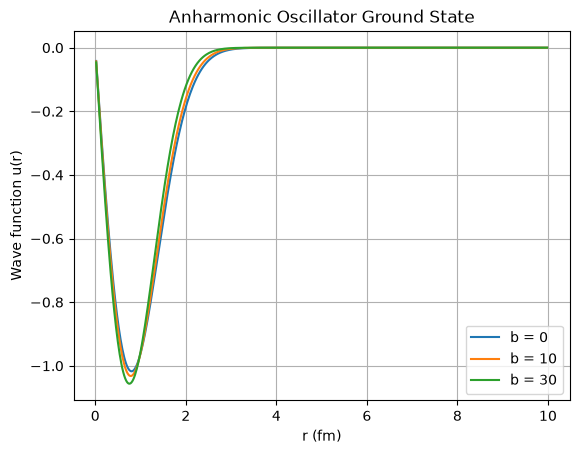

In [1]:
import numpy as np
import matplotlib.pyplot as plt

m = 940
hbar = 197.3
k = 100

h = hbar**2/(2*m)

N = 500
r_max = 10

r = np.linspace(0, r_max, N+2)[1:-1]
dr = r[1] - r[0]

b_values = [0, 10, 30]

for b in b_values:

    V = 0.5*k*r**2 + (b/3)*r**3

    H = np.diag(2*h/dr**2 + V)
    H += np.diag(-h/dr**2*np.ones(N-1), 1)
    H += np.diag(-h/dr**2*np.ones(N-1), -1)

    E, psi = np.linalg.eigh(H)

    u = psi[:, 0]
    u = u/np.sqrt(np.trapezoid(u**2, r))

    print("b =", b, "MeV fm^-3")
    print("Ground state energy =", round(E[0], 3), "MeV")

    plt.plot(r, u, label="b = "+str(b))

plt.xlabel("r (fm)")
plt.ylabel("Wave function u(r)")
plt.title("Anharmonic Oscillator Ground State")
plt.legend()
plt.grid()
plt.show()

Lowest vibrational energy = -0.161436 eV
Lowest vibrational energy = -1.61e-07 MeV


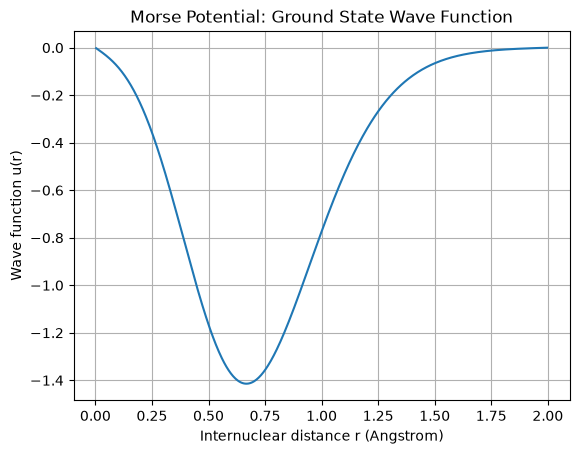

In [3]:
import numpy as np
import matplotlib.pyplot as plt

m = 940e6
hbar = 1973

D = 0.755501
alpha = 1.44
r0 = 0.131349

h = hbar**2/(2*m)

N = 600
r_max = 2

r = np.linspace(0, r_max, N+2)[1:-1]
dr = r[1] - r[0]

rp = r - r0

V = D*(np.exp(-2*alpha*rp) - np.exp(-alpha*rp))

H = np.diag(2*h/dr**2 + V)
H += np.diag(-h/dr**2*np.ones(N-1), 1)
H += np.diag(-h/dr**2*np.ones(N-1), -1)

E, psi = np.linalg.eigh(H)

u = psi[:, 0]
u = u/np.sqrt(np.trapezoid(u**2, r))

print("Lowest vibrational energy =", round(E[0], 6), "eV")
print("Lowest vibrational energy =", round(E[0]/1e6, 9), "MeV")

plt.plot(r, u)
plt.xlabel("Internuclear distance r (Angstrom)")
plt.ylabel("Wave function u(r)")
plt.title("Morse Potential: Ground State Wave Function")
plt.grid()
plt.show()